# Top ratings and airline passenger satisfaction: SHAP attribution patterns by travel purpose

This notebook (1) compares four tuned models under leakage-free 5-fold cross-validation, with every preprocessing step and the hyperparameter search inside the training fold, and (2) uses out-of-fold SHAP values to describe how the model's attribution for each of the 14 service attributes changes across the rating scale, and how the contrast between ratings of 4–5 and 1–3 differs between business and personal travellers and between returning and first-time customers. A penalty-reward analysis is included as a supplementary check.

A rating of **0** lies outside the 1–5 scale and is treated as "not applicable" (missing), not as a very low score.

Run all cells in order. A GPU is not needed. Results are saved to `results_air/` and zipped at the end (Colab only).

## 1. Data preparation

In [1]:
# Cell 1: Imports and settings
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
import shap
from scipy.stats import friedmanchisquare
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, classification_report)

warnings.filterwarnings('ignore')
SEED = 42
N_FOLDS = 5
DATA_PATH = 'airline_passenger_satisfaction.csv'
OUT_DIR = 'results_air'
os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)
print('XGBoost', xgb.__version__, '| LightGBM', lgb.__version__, '| SHAP', shap.__version__)

XGBoost 3.4.1 | LightGBM 4.6.0 | SHAP 0.52.0


In [2]:
# Cell 2: Load data and check duplicates, missing values and class balance
df = pd.read_csv(DATA_PATH)
print('Records:', len(df), '| Columns:', df.shape[1])
print('Exact duplicates (ignoring ID):', df.drop(columns=['ID']).duplicated().sum())
print('Missing values:'); print(df.isna().sum()[df.isna().sum() > 0])
print(df['Satisfaction'].value_counts(normalize=True).round(4))

Records: 129880 | Columns: 24
Exact duplicates (ignoring ID): 0
Missing values:
Arrival Delay    393
dtype: int64
Satisfaction
Neutral or Dissatisfied    0.5655
Satisfied                  0.4345
Name: proportion, dtype: float64


In [3]:
# Cell 3: Service ratings - 0 means "not applicable", so it is set to missing
service_cols = ['Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service',
                'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service',
                'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service',
                'In-flight Entertainment', 'Baggage Handling']
zero_counts = (df[service_cols] == 0).sum().sort_values(ascending=False)
print('Ratings of 0 (not applicable) per attribute:'); print(zero_counts[zero_counts > 0].to_string())
rows_with_zero = (df[service_cols] == 0).any(axis=1).sum()
print(f'Passengers with at least one 0 rating: {rows_with_zero:,} ({rows_with_zero / len(df):.1%})')
df_raw_ratings = df[service_cols].copy()          # kept for the sensitivity check in section 7
df[service_cols] = df[service_cols].replace(0, np.nan)
zero_counts.rename('Zero (not applicable) ratings').to_csv(f'{OUT_DIR}/table_zero_ratings.csv')

Ratings of 0 (not applicable) per attribute:
Departure and Arrival Time Convenience    6681
Ease of Online Booking                    5682
In-flight Wifi Service                    3916
Online Boarding                           3080
Leg Room Service                           598
Food and Drink                             132
In-flight Entertainment                     18
Cleanliness                                 14
On-board Service                             5
In-flight Service                            5
Gate Location                                1
Check-in Service                             1
Seat Comfort                                 1
Passengers with at least one 0 rating: 10,313 (7.9%)


In [4]:
# Cell 4: Target, features and one-hot encoding (label-free, so it can be done before splitting)
y = (df['Satisfaction'] == 'Satisfied').astype(int).values
cat_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
segments = df[['Type of Travel', 'Customer Type', 'Class']].copy()      # kept for the segment analysis
X = pd.get_dummies(df.drop(columns=['ID', 'Satisfaction']), columns=cat_cols, dtype=float).astype('float32')
feature_names = X.columns.tolist()
num_cols = ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay'] + service_cols
print('Features after encoding:', X.shape[1], '| Satisfied share:', round(y.mean(), 4))

# Satisfaction rate by segment (descriptive table for the paper)
seg_table = (df.assign(sat=y).groupby(['Type of Travel', 'Class'])['sat'].agg(['size', 'mean'])
               .rename(columns={'size': 'Passengers', 'mean': 'Satisfied share'}).round(3))
seg_table.to_csv(f'{OUT_DIR}/table_segments.csv')
seg_table

Features after encoding: 27 | Satisfied share: 0.4345


Passengers  Satisfied share
Type of Travel Class                                    
Business       Business           59487            0.720
               Economy            25304            0.299
               Economy Plus        4902            0.393
Personal       Business            2673            0.117
               Economy            33005            0.102
               Economy Plus        4509            0.087

In [5]:
# Cell 5: Random-search configurations (drawn once, the same list in every fold)
rng = np.random.RandomState(SEED)
lr_grid = [0.01, 0.1, 1.0, 10.0]
rf_configs = [{'max_depth': [None, 20, 30][rng.randint(3)], 'min_samples_leaf': int(rng.choice([1, 2, 5])),
               'max_features': ['sqrt', 0.3][rng.randint(2)]} for _ in range(4)]
xgb_configs = [{'max_depth': int(rng.choice([4, 6, 8, 10])), 'learning_rate': float(rng.choice([0.03, 0.05, 0.1])),
                'subsample': float(rng.choice([0.7, 0.8, 1.0])), 'colsample_bytree': float(rng.choice([0.6, 0.8, 1.0])),
                'min_child_weight': int(rng.choice([1, 3, 5])), 'reg_lambda': float(rng.choice([0.5, 1.0, 5.0]))}
               for _ in range(10)]
lgb_configs = [{'num_leaves': int(rng.choice([31, 63, 127, 255])), 'learning_rate': float(rng.choice([0.03, 0.05, 0.1])),
                'min_child_samples': int(rng.choice([10, 20, 50])), 'colsample_bytree': float(rng.choice([0.6, 0.8, 1.0])),
                'subsample': float(rng.choice([0.7, 0.8, 1.0])), 'reg_lambda': float(rng.choice([0.0, 1.0, 5.0]))}
               for _ in range(10)]
pd.DataFrame(rf_configs).to_csv(f'{OUT_DIR}/search_space_rf.csv', index_label='config')
pd.DataFrame(xgb_configs).to_csv(f'{OUT_DIR}/search_space_xgboost.csv', index_label='config')
pd.DataFrame(lgb_configs).to_csv(f'{OUT_DIR}/search_space_lightgbm.csv', index_label='config')
print(len(lr_grid), 'LR values |', len(rf_configs), 'RF |', len(xgb_configs), 'XGBoost |', len(lgb_configs), 'LightGBM configurations')

4 LR values | 4 RF | 10 XGBoost | 10 LightGBM configurations


In [6]:
# Cell 6: Prepare the 5 folds. All learned steps are fitted on the training part only.
# Tree boosting models get the data with missing values left as NaN (they handle it natively).
# Logistic regression and random forest get median imputation + missing-value indicators;
# logistic regression is also scaled. The class split (43/57) is mild, so no oversampling is used.
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = []
for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), start=1):
    X_tr, X_te = X.iloc[tr_idx].copy(), X.iloc[te_idx].copy()
    y_tr, y_te = y[tr_idx], y[te_idx]
    # inner validation split: used for choosing hyperparameters and for early stopping
    X_in, X_val, y_in, y_val = train_test_split(X_tr, y_tr, test_size=0.1, stratify=y_tr, random_state=SEED)
    # imputed copies (medians from the inner training data only)
    med = X_in[num_cols].median()
    imp = {}
    for name, part in [('in', X_in), ('val', X_val), ('te', X_te)]:
        p = part.copy()
        for c in service_cols + ['Arrival Delay']:
            p[c + ' (missing)'] = p[c].isna().astype('float32')
        p[num_cols] = p[num_cols].fillna(med)
        imp[name] = p
    scaler = StandardScaler().fit(imp['in'])
    folds.append({'te_idx': te_idx, 'y_in': y_in, 'y_val': y_val, 'y_te': y_te,
                  'raw_in': X_in, 'raw_val': X_val, 'raw_te': X_te,
                  'imp_in': imp['in'], 'imp_val': imp['val'], 'imp_te': imp['te'],
                  'sc_in': scaler.transform(imp['in']), 'sc_val': scaler.transform(imp['val']),
                  'sc_te': scaler.transform(imp['te'])})
    print(f'Fold {fold}: train {len(y_in):,} | validation {len(y_val):,} | test {len(y_te):,}')

Fold 1: train 93,513 | validation 10,391 | test 25,976
Fold 2: train 93,513 | validation 10,391 | test 25,976
Fold 3: train 93,513 | validation 10,391 | test 25,976
Fold 4: train 93,513 | validation 10,391 | test 25,976
Fold 5: train 93,513 | validation 10,391 | test 25,976


In [7]:
# Cell 7: Shared containers
model_names = ['Logistic Regression', 'Random Forest', 'XGBoost', 'LightGBM']
results_rows = []
oof_proba = {m: np.full(len(y), np.nan) for m in model_names}
chosen = []
best_models = {}

## 2. Logistic Regression

In [8]:
# Cell 8: Train Logistic Regression (C chosen inside each fold on the validation set)
m = 'Logistic Regression'
results_rows = [r for r in results_rows if r['Model'] != m]
chosen = [c for c in chosen if c['Model'] != m]
for s, f in enumerate(folds):
    t_start = time.time()
    best_auc = -1
    for ci, C in enumerate(lr_grid):
        model = LogisticRegression(C=C, max_iter=3000, random_state=SEED).fit(f['sc_in'], f['y_in'])
        val_auc = roc_auc_score(f['y_val'], model.predict_proba(f['sc_val'])[:, 1])
        if val_auc > best_auc:
            best_auc, best_cfg, best_params = val_auc, ci, {'C': C}
            best_p = model.predict_proba(f['sc_te'])[:, 1]

    oof_proba[m][f['te_idx']] = best_p
    pred = (best_p >= 0.5).astype(int)
    results_rows.append({'Model': m, 'Fold': s + 1, 'Accuracy': accuracy_score(f['y_te'], pred),
                         'Precision': precision_score(f['y_te'], pred), 'Recall': recall_score(f['y_te'], pred),
                         'F1': f1_score(f['y_te'], pred), 'ROC-AUC': roc_auc_score(f['y_te'], best_p),
                         'PR-AUC': average_precision_score(f['y_te'], best_p), 'Chosen config': best_cfg,
                         'Validation ROC-AUC': best_auc})
    chosen.append({'Model': m, 'Fold': s + 1, 'Validation ROC-AUC': round(best_auc, 4), **best_params})
    print(f"Fold {s + 1}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={accuracy_score(f['y_te'], pred):.4f}  "
          f"F1={f1_score(f['y_te'], pred):.4f}  AUC={roc_auc_score(f['y_te'], best_p):.4f}  ({time.time() - t_start:.0f}s)")

Fold 1: config=2  val AUC=0.9657  test Acc=0.9030  F1=0.8880  AUC=0.9649  (5s)
Fold 2: config=3  val AUC=0.9641  test Acc=0.9010  F1=0.8853  AUC=0.9633  (4s)
Fold 3: config=3  val AUC=0.9675  test Acc=0.9054  F1=0.8915  AUC=0.9662  (4s)
Fold 4: config=3  val AUC=0.9665  test Acc=0.9007  F1=0.8857  AUC=0.9648  (4s)
Fold 5: config=3  val AUC=0.9653  test Acc=0.9060  F1=0.8916  AUC=0.9656  (4s)


===== Logistic Regression: results per fold =====
 Fold  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Chosen config  Validation ROC-AUC
    1    0.9030     0.8910  0.8850 0.8880   0.9649  0.9584              2              0.9657
    2    0.9010     0.8910  0.8798 0.8853   0.9633  0.9562              3              0.9641
    3    0.9054     0.8886  0.8945 0.8915   0.9662  0.9589              3              0.9675
    4    0.9007     0.8857  0.8858 0.8857   0.9648  0.9573              3              0.9665
    5    0.9060     0.8937  0.8895 0.8916   0.9656  0.9586              3              0.9653

Mean ± std:
  Accuracy   0.9032 ± 0.0025
  Precision  0.8900 ± 0.0030
  Recall     0.8869 ± 0.0055
  F1         0.8884 ± 0.0030
  ROC-AUC    0.9650 ± 0.0011
  PR-AUC     0.9579 ± 0.0011

===== Logistic Regression: classification report (pooled test predictions) =====
                      precision    recall  f1-score   support

Neutral/dissatisfied     0.9133    0.9158    0.9146   

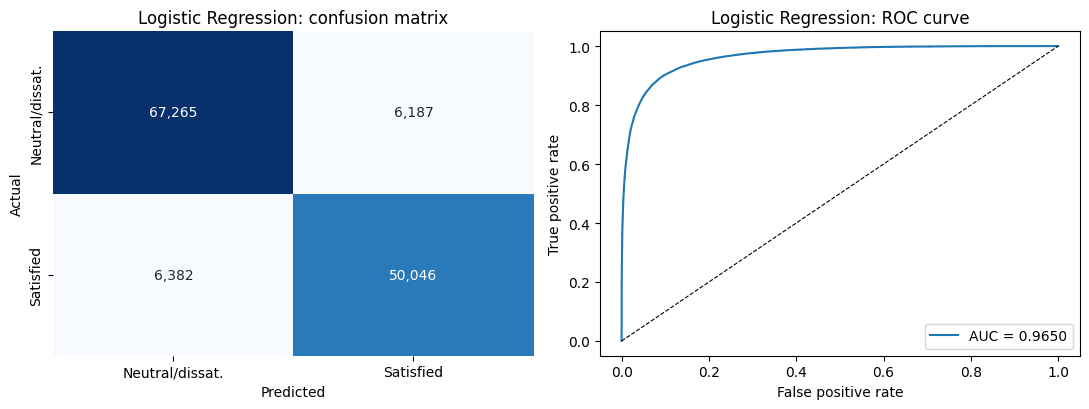

In [9]:
# Cell 9: Evaluate Logistic Regression
m = 'Logistic Regression'
tag = 'logreg'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per fold =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {k:<10} {res[k].mean():.4f} ± {res[k].std():.4f}')
pred = (oof_proba[m] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y, pred, target_names=['Neutral/dissatisfied', 'Satisfied'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(confusion_matrix(y, pred), annot=True, fmt=',', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Neutral/dissat.', 'Satisfied'], yticklabels=['Neutral/dissat.', 'Satisfied'])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual'); axes[0].set_title(f'{m}: confusion matrix')
fpr, tpr, _ = roc_curve(y, oof_proba[m])
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y, oof_proba[m]):.4f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate'); axes[1].set_title(f'{m}: ROC curve')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()

## 3. Random Forest

In [10]:
# Cell 10: Train Random Forest (configuration chosen inside each fold on the validation set)
m = 'Random Forest'
results_rows = [r for r in results_rows if r['Model'] != m]
chosen = [c for c in chosen if c['Model'] != m]
for s, f in enumerate(folds):
    t_start = time.time()
    best_auc = -1
    for ci, c in enumerate(rf_configs):
        model = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, **c).fit(f['imp_in'], f['y_in'])
        val_auc = roc_auc_score(f['y_val'], model.predict_proba(f['imp_val'])[:, 1])
        if val_auc > best_auc:
            best_auc, best_cfg, best_params = val_auc, ci, dict(c)
            best_p = model.predict_proba(f['imp_te'])[:, 1]
        del model

    oof_proba[m][f['te_idx']] = best_p
    pred = (best_p >= 0.5).astype(int)
    results_rows.append({'Model': m, 'Fold': s + 1, 'Accuracy': accuracy_score(f['y_te'], pred),
                         'Precision': precision_score(f['y_te'], pred), 'Recall': recall_score(f['y_te'], pred),
                         'F1': f1_score(f['y_te'], pred), 'ROC-AUC': roc_auc_score(f['y_te'], best_p),
                         'PR-AUC': average_precision_score(f['y_te'], best_p), 'Chosen config': best_cfg,
                         'Validation ROC-AUC': best_auc})
    chosen.append({'Model': m, 'Fold': s + 1, 'Validation ROC-AUC': round(best_auc, 4), **best_params})
    print(f"Fold {s + 1}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={accuracy_score(f['y_te'], pred):.4f}  "
          f"F1={f1_score(f['y_te'], pred):.4f}  AUC={roc_auc_score(f['y_te'], best_p):.4f}  ({time.time() - t_start:.0f}s)")

Fold 1: config=0  val AUC=0.9943  test Acc=0.9639  F1=0.9579  AUC=0.9946  (99s)
Fold 2: config=0  val AUC=0.9937  test Acc=0.9610  F1=0.9542  AUC=0.9940  (94s)
Fold 3: config=0  val AUC=0.9947  test Acc=0.9645  F1=0.9586  AUC=0.9946  (89s)
Fold 4: config=0  val AUC=0.9945  test Acc=0.9615  F1=0.9550  AUC=0.9940  (86s)
Fold 5: config=0  val AUC=0.9945  test Acc=0.9623  F1=0.9560  AUC=0.9940  (87s)


===== Random Forest: results per fold =====
 Fold  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Chosen config  Validation ROC-AUC
    1    0.9639     0.9715  0.9447 0.9579   0.9946  0.9937              0              0.9943
    2    0.9610     0.9734  0.9357 0.9542   0.9940  0.9931              0              0.9937
    3    0.9645     0.9719  0.9458 0.9586   0.9946  0.9938              0              0.9947
    4    0.9615     0.9689  0.9415 0.9550   0.9940  0.9930              0              0.9945
    5    0.9623     0.9721  0.9404 0.9560   0.9940  0.9930              0              0.9945

Mean ± std:
  Accuracy   0.9627 ± 0.0015
  Precision  0.9716 ± 0.0017
  Recall     0.9416 ± 0.0040
  F1         0.9563 ± 0.0019
  ROC-AUC    0.9942 ± 0.0003
  PR-AUC     0.9933 ± 0.0004

===== Random Forest: classification report (pooled test predictions) =====
                      precision    recall  f1-score   support

Neutral/dissatisfied     0.9562    0.9788    0.9674     73452
    

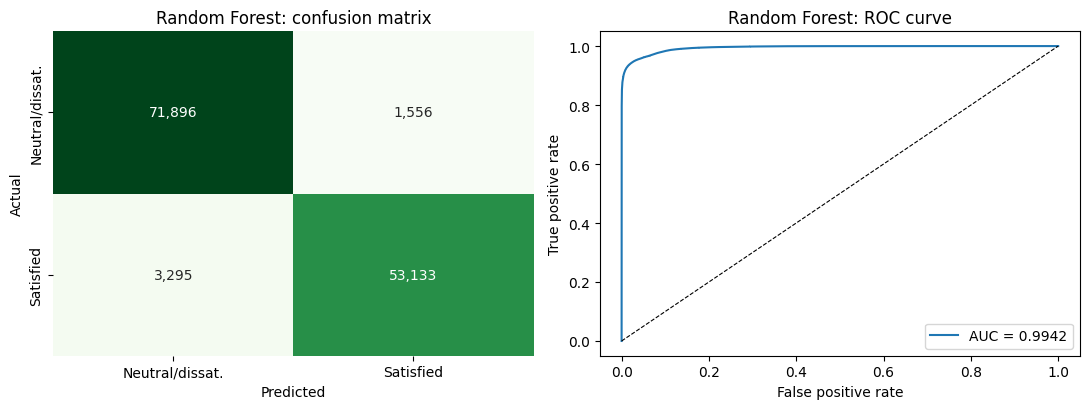

In [11]:
# Cell 11: Evaluate Random Forest
m = 'Random Forest'
tag = 'rf'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per fold =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {k:<10} {res[k].mean():.4f} ± {res[k].std():.4f}')
pred = (oof_proba[m] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y, pred, target_names=['Neutral/dissatisfied', 'Satisfied'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(confusion_matrix(y, pred), annot=True, fmt=',', cmap='Greens', cbar=False, ax=axes[0],
            xticklabels=['Neutral/dissat.', 'Satisfied'], yticklabels=['Neutral/dissat.', 'Satisfied'])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual'); axes[0].set_title(f'{m}: confusion matrix')
fpr, tpr, _ = roc_curve(y, oof_proba[m])
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y, oof_proba[m]):.4f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate'); axes[1].set_title(f'{m}: ROC curve')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()

## 4. XGBoost

In [12]:
# Cell 12: Train XGBoost (random search inside each fold; early stopping on the validation set)
m = 'XGBoost'
results_rows = [r for r in results_rows if r['Model'] != m]
chosen = [c for c in chosen if c['Model'] != m]
for s, f in enumerate(folds):
    t_start = time.time()
    best_auc = -1
    for ci, c in enumerate(xgb_configs):
        model = xgb.XGBClassifier(n_estimators=2000, eval_metric='logloss', early_stopping_rounds=50,
                                  tree_method='hist', random_state=SEED, n_jobs=-1, **c)
        model.fit(f['raw_in'], f['y_in'], eval_set=[(f['raw_val'], f['y_val'])], verbose=False)
        val_auc = roc_auc_score(f['y_val'], model.predict_proba(f['raw_val'])[:, 1])
        if val_auc > best_auc:
            best_auc, best_cfg, best_params = val_auc, ci, dict(c)
            best_p = model.predict_proba(f['raw_te'])[:, 1]

    oof_proba[m][f['te_idx']] = best_p
    pred = (best_p >= 0.5).astype(int)
    results_rows.append({'Model': m, 'Fold': s + 1, 'Accuracy': accuracy_score(f['y_te'], pred),
                         'Precision': precision_score(f['y_te'], pred), 'Recall': recall_score(f['y_te'], pred),
                         'F1': f1_score(f['y_te'], pred), 'ROC-AUC': roc_auc_score(f['y_te'], best_p),
                         'PR-AUC': average_precision_score(f['y_te'], best_p), 'Chosen config': best_cfg,
                         'Validation ROC-AUC': best_auc})
    chosen.append({'Model': m, 'Fold': s + 1, 'Validation ROC-AUC': round(best_auc, 4), **best_params})
    print(f"Fold {s + 1}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={accuracy_score(f['y_te'], pred):.4f}  "
          f"F1={f1_score(f['y_te'], pred):.4f}  AUC={roc_auc_score(f['y_te'], best_p):.4f}  ({time.time() - t_start:.0f}s)")

Fold 1: config=0  val AUC=0.9959  test Acc=0.9662  F1=0.9606  AUC=0.9958  (123s)
Fold 2: config=0  val AUC=0.9951  test Acc=0.9646  F1=0.9585  AUC=0.9955  (104s)
Fold 3: config=0  val AUC=0.9959  test Acc=0.9670  F1=0.9614  AUC=0.9958  (120s)
Fold 4: config=9  val AUC=0.9960  test Acc=0.9638  F1=0.9577  AUC=0.9953  (116s)
Fold 5: config=5  val AUC=0.9961  test Acc=0.9638  F1=0.9576  AUC=0.9954  (112s)


===== XGBoost: results per fold =====
 Fold  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Chosen config  Validation ROC-AUC
    1    0.9662     0.9740  0.9475 0.9606   0.9958  0.9950              0              0.9959
    2    0.9646     0.9775  0.9402 0.9585   0.9955  0.9946              0              0.9951
    3    0.9670     0.9755  0.9478 0.9614   0.9958  0.9951              0              0.9959
    4    0.9638     0.9722  0.9436 0.9577   0.9953  0.9944              9              0.9960
    5    0.9638     0.9743  0.9414 0.9576   0.9954  0.9945              5              0.9961

Mean ± std:
  Accuracy   0.9651 ± 0.0014
  Precision  0.9747 ± 0.0020
  Recall     0.9441 ± 0.0035
  F1         0.9592 ± 0.0017
  ROC-AUC    0.9956 ± 0.0002
  PR-AUC     0.9947 ± 0.0003

===== XGBoost: classification report (pooled test predictions) =====
                      precision    recall  f1-score   support

Neutral/dissatisfied     0.9581    0.9812    0.9695     73452
           Satis

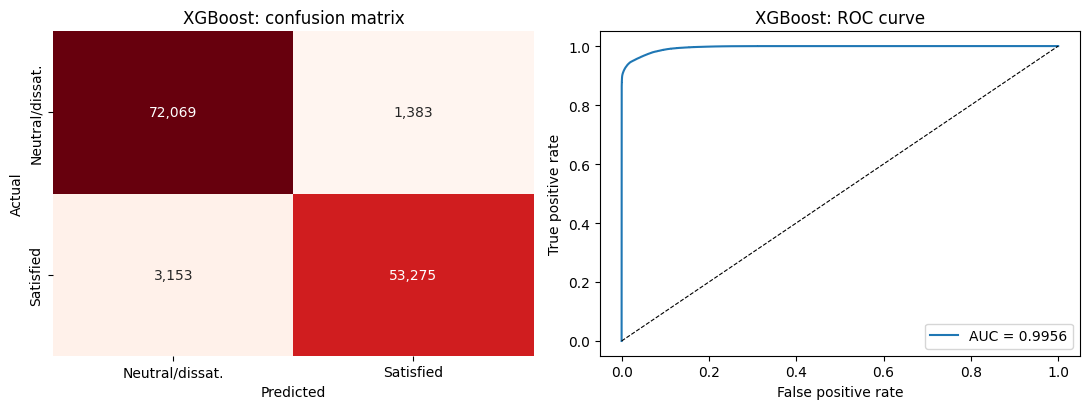

In [13]:
# Cell 13: Evaluate XGBoost
m = 'XGBoost'
tag = 'xgboost'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per fold =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {k:<10} {res[k].mean():.4f} ± {res[k].std():.4f}')
pred = (oof_proba[m] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y, pred, target_names=['Neutral/dissatisfied', 'Satisfied'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(confusion_matrix(y, pred), annot=True, fmt=',', cmap='Reds', cbar=False, ax=axes[0],
            xticklabels=['Neutral/dissat.', 'Satisfied'], yticklabels=['Neutral/dissat.', 'Satisfied'])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual'); axes[0].set_title(f'{m}: confusion matrix')
fpr, tpr, _ = roc_curve(y, oof_proba[m])
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y, oof_proba[m]):.4f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate'); axes[1].set_title(f'{m}: ROC curve')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()

## 5. LightGBM

In [14]:
# Cell 14: Train LightGBM (random search inside each fold; early stopping on the validation set)
m = 'LightGBM'
results_rows = [r for r in results_rows if r['Model'] != m]
chosen = [c for c in chosen if c['Model'] != m]
for s, f in enumerate(folds):
    t_start = time.time()
    best_auc = -1
    for ci, c in enumerate(lgb_configs):
        model = lgb.LGBMClassifier(n_estimators=2000, subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1, **c)
        model.fit(f['raw_in'], f['y_in'], eval_set=[(f['raw_val'], f['y_val'])], eval_metric='binary_logloss',
                  callbacks=[lgb.early_stopping(50, verbose=False)])
        val_auc = roc_auc_score(f['y_val'], model.predict_proba(f['raw_val'])[:, 1])
        if val_auc > best_auc:
            best_auc, best_cfg, best_params = val_auc, ci, dict(c)
            best_p = model.predict_proba(f['raw_te'])[:, 1]
            best_models[s] = model

    oof_proba[m][f['te_idx']] = best_p
    pred = (best_p >= 0.5).astype(int)
    results_rows.append({'Model': m, 'Fold': s + 1, 'Accuracy': accuracy_score(f['y_te'], pred),
                         'Precision': precision_score(f['y_te'], pred), 'Recall': recall_score(f['y_te'], pred),
                         'F1': f1_score(f['y_te'], pred), 'ROC-AUC': roc_auc_score(f['y_te'], best_p),
                         'PR-AUC': average_precision_score(f['y_te'], best_p), 'Chosen config': best_cfg,
                         'Validation ROC-AUC': best_auc})
    chosen.append({'Model': m, 'Fold': s + 1, 'Validation ROC-AUC': round(best_auc, 4), **best_params})
    print(f"Fold {s + 1}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={accuracy_score(f['y_te'], pred):.4f}  "
          f"F1={f1_score(f['y_te'], pred):.4f}  AUC={roc_auc_score(f['y_te'], best_p):.4f}  ({time.time() - t_start:.0f}s)")

Fold 1: config=5  val AUC=0.9960  test Acc=0.9674  F1=0.9619  AUC=0.9960  (59s)
Fold 2: config=0  val AUC=0.9952  test Acc=0.9646  F1=0.9585  AUC=0.9955  (49s)
Fold 3: config=5  val AUC=0.9960  test Acc=0.9674  F1=0.9620  AUC=0.9961  (59s)
Fold 4: config=5  val AUC=0.9960  test Acc=0.9648  F1=0.9588  AUC=0.9955  (57s)
Fold 5: config=5  val AUC=0.9963  test Acc=0.9654  F1=0.9594  AUC=0.9956  (61s)


===== LightGBM: results per fold =====
 Fold  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Chosen config  Validation ROC-AUC
    1    0.9674     0.9776  0.9467 0.9619   0.9960  0.9952              5              0.9960
    2    0.9646     0.9773  0.9404 0.9585   0.9955  0.9946              0              0.9952
    3    0.9674     0.9760  0.9483 0.9620   0.9961  0.9953              5              0.9960
    4    0.9648     0.9750  0.9431 0.9588   0.9955  0.9946              5              0.9960
    5    0.9654     0.9769  0.9425 0.9594   0.9956  0.9948              5              0.9963

Mean ± std:
  Accuracy   0.9659 ± 0.0014
  Precision  0.9766 ± 0.0011
  Recall     0.9442 ± 0.0033
  F1         0.9601 ± 0.0017
  ROC-AUC    0.9957 ± 0.0002
  PR-AUC     0.9949 ± 0.0003

===== LightGBM: classification report (pooled test predictions) =====
                      precision    recall  f1-score   support

Neutral/dissatisfied     0.9582    0.9826    0.9702     73452
           Sat

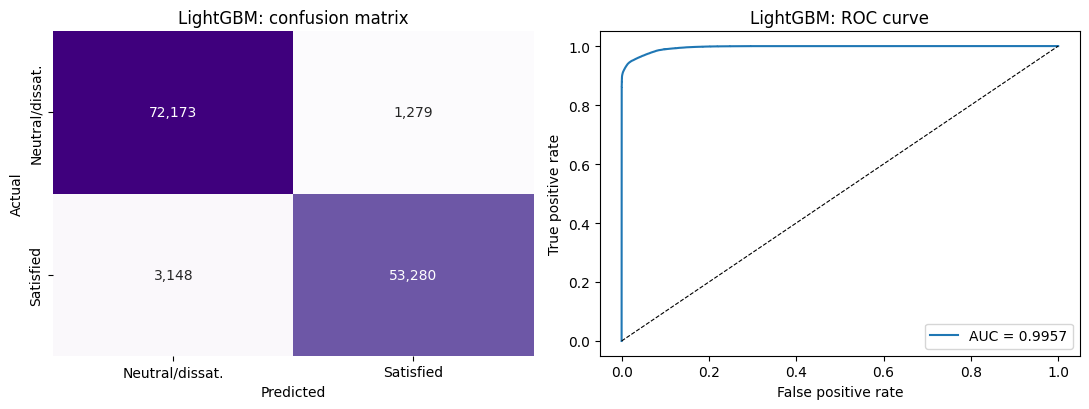

In [15]:
# Cell 15: Evaluate LightGBM
m = 'LightGBM'
tag = 'lightgbm'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per fold =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {k:<10} {res[k].mean():.4f} ± {res[k].std():.4f}')
pred = (oof_proba[m] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y, pred, target_names=['Neutral/dissatisfied', 'Satisfied'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(confusion_matrix(y, pred), annot=True, fmt=',', cmap='Purples', cbar=False, ax=axes[0],
            xticklabels=['Neutral/dissat.', 'Satisfied'], yticklabels=['Neutral/dissat.', 'Satisfied'])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual'); axes[0].set_title(f'{m}: confusion matrix')
fpr, tpr, _ = roc_curve(y, oof_proba[m])
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y, oof_proba[m]):.4f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate'); axes[1].set_title(f'{m}: ROC curve')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()

## 6. Comparison of all models

                            Accuracy        Precision           Recall               F1          ROC-AUC           PR-AUC
Model                                                                                                                    
Logistic Regression  0.9032 ± 0.0025     0.89 ± 0.003  0.8869 ± 0.0055   0.8884 ± 0.003   0.965 ± 0.0011  0.9579 ± 0.0011
Random Forest        0.9627 ± 0.0015  0.9716 ± 0.0017   0.9416 ± 0.004  0.9563 ± 0.0019  0.9942 ± 0.0003  0.9933 ± 0.0004
XGBoost              0.9651 ± 0.0014   0.9747 ± 0.002  0.9441 ± 0.0035  0.9592 ± 0.0017  0.9956 ± 0.0002  0.9947 ± 0.0003
LightGBM             0.9659 ± 0.0014  0.9766 ± 0.0011  0.9442 ± 0.0033  0.9601 ± 0.0017  0.9957 ± 0.0002  0.9949 ± 0.0003

Friedman test on F1 across folds: chi2 = 14.040, p = 0.002851
McNemar LightGBM vs XGBoost: chi2 = 11.723, p = 0.000617; only LightGBM correct: 552, only XGBoost correct: 443


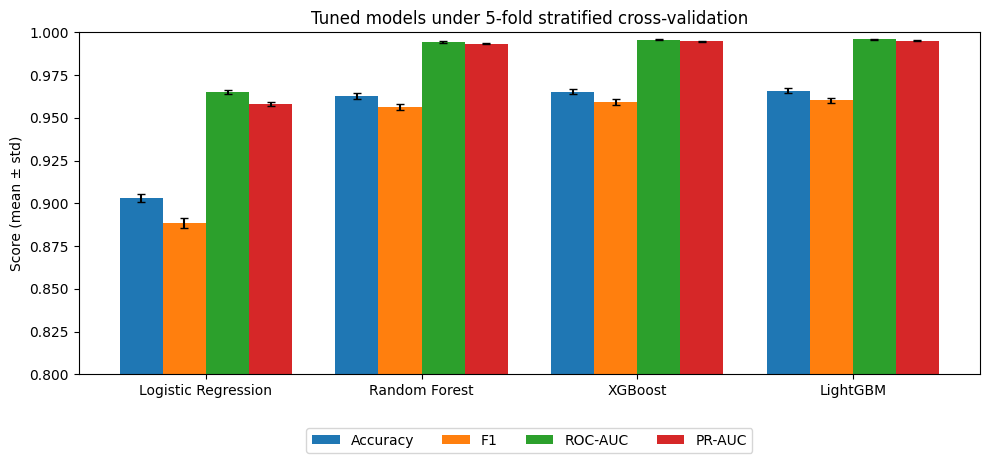

In [16]:
# Cell 16: Main results table, chosen hyperparameters and statistical tests
results_df = pd.DataFrame(results_rows)
results_df.to_csv(f'{OUT_DIR}/fold_results.csv', index=False)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
mean_df = results_df.groupby('Model')[metrics].mean().loc[model_names]
std_df = results_df.groupby('Model')[metrics].std().loc[model_names]
main_table = mean_df.round(4).astype(str) + ' ± ' + std_df.round(4).astype(str)
main_table.to_csv(f'{OUT_DIR}/table_main_results.csv')
print(main_table.to_string())
chosen_df = pd.DataFrame(chosen)
chosen_df.to_csv(f'{OUT_DIR}/table_chosen_hyperparameters.csv', index=False)

f1_matrix = results_df.pivot(index='Fold', columns='Model', values='F1')[model_names]
stat, p_friedman = friedmanchisquare(*[f1_matrix[c] for c in model_names])
print(f'\nFriedman test on F1 across folds: chi2 = {stat:.3f}, p = {p_friedman:.4g}')
best_two = mean_df['F1'].sort_values(ascending=False).index[:2].tolist()
c1 = (oof_proba[best_two[0]] >= 0.5) == y
c2 = (oof_proba[best_two[1]] >= 0.5) == y
mc_table = [[int(np.sum(c1 & c2)), int(np.sum(c1 & ~c2))], [int(np.sum(~c1 & c2)), int(np.sum(~c1 & ~c2))]]
mc = mcnemar(mc_table, exact=False, correction=True)
print(f'McNemar {best_two[0]} vs {best_two[1]}: chi2 = {mc.statistic:.3f}, p = {mc.pvalue:.3g}; '
      f'only {best_two[0]} correct: {mc_table[0][1]}, only {best_two[1]} correct: {mc_table[1][0]}')
pd.DataFrame([{'Test': 'Friedman (F1)', 'Statistic': stat, 'p-value': p_friedman},
              {'Test': f'McNemar ({best_two[0]} vs {best_two[1]})', 'Statistic': mc.statistic, 'p-value': mc.pvalue,
               'Detail': f'only {best_two[0]} correct: {mc_table[0][1]}; only {best_two[1]} correct: {mc_table[1][0]}'}]
             ).to_csv(f'{OUT_DIR}/table_statistical_tests.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 4.8))
x_pos = np.arange(len(model_names)); w = 0.2
for i, met in enumerate(['Accuracy', 'F1', 'ROC-AUC', 'PR-AUC']):
    ax.bar(x_pos + (i - 1.5) * w, mean_df[met], w, yerr=std_df[met], capsize=3, label=met)
ax.set_xticks(x_pos); ax.set_xticklabels(model_names); ax.set_ylim(0.8, 1.0)
ax.set_ylabel('Score (mean ± std)'); ax.legend(ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.25))
ax.set_title('Tuned models under 5-fold stratified cross-validation')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_model_comparison.png', dpi=300); plt.show()

## 7. Sensitivity check: treating 0 as a real score

In [17]:
# Cell 17: LightGBM with the chosen fold configurations, but 0 ratings kept as scores (the usual practice)
X_zero = X.copy()
X_zero[service_cols] = df_raw_ratings.values
rows = []
for s, (tr_idx, te_idx) in enumerate(skf.split(X, y)):
    cfg = lgb_configs[int(results_df[(results_df['Model'] == 'LightGBM') & (results_df['Fold'] == s + 1)]['Chosen config'].iloc[0])]
    Xa, Xv, ya, yv = train_test_split(X_zero.iloc[tr_idx], y[tr_idx], test_size=0.1, stratify=y[tr_idx], random_state=SEED)
    model = lgb.LGBMClassifier(n_estimators=2000, subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1, **cfg)
    model.fit(Xa, ya, eval_set=[(Xv, yv)], eval_metric='binary_logloss', callbacks=[lgb.early_stopping(50, verbose=False)])
    p = model.predict_proba(X_zero.iloc[te_idx])[:, 1]
    rows.append({'Fold': s + 1, 'F1': f1_score(y[te_idx], p >= 0.5), 'ROC-AUC': roc_auc_score(y[te_idx], p)})
zero_df = pd.DataFrame(rows)
lgb_main = results_df[results_df['Model'] == 'LightGBM']
sens = pd.DataFrame({'Setting': ['0 = not applicable (missing), this study', '0 kept as a score'],
                     'F1': [lgb_main['F1'].mean(), zero_df['F1'].mean()],
                     'ROC-AUC': [lgb_main['ROC-AUC'].mean(), zero_df['ROC-AUC'].mean()]}).round(4)
sens.to_csv(f'{OUT_DIR}/table_zero_sensitivity.csv', index=False)
print(sens.to_string(index=False))

                                 Setting     F1  ROC-AUC
0 = not applicable (missing), this study 0.9601   0.9957
                       0 kept as a score 0.9599   0.9957


## 8. SHAP: penalty and reward of each service attribute

SHAP values come from the LightGBM model chosen in each fold, explaining 3,000 random **test** passengers from that fold (15,000 in total), so every passenger is explained by a model that did not train on them.

For each attribute and segment, rating 3 is the reference: the **penalty** is how much ratings 1–2 lower satisfaction compared with 3, and the **reward** is how much ratings 4–5 raise it (each set to 0 if it goes the other way). The impact-asymmetry index is IA = (reward − penalty) / (reward + penalty): below −0.2 the attribute behaves as a **basic** factor (mainly hurts when poor), above +0.2 as an **excitement** factor (mainly helps when good), otherwise as a **performance** factor. Attributes whose total effect is below 0.1 log-odds are marked weak, and attributes where higher ratings go with lower satisfaction are marked reversed. 95% intervals come from 500 bootstrap resamples of passengers.

Fold 1: SHAP done (91s)
Fold 2: SHAP done (24s)
Fold 3: SHAP done (83s)
Fold 4: SHAP done (73s)
Fold 5: SHAP done (87s)
In-flight Wifi Service      2.1853
Type of Travel_Business     1.9934
Online Boarding             1.3132
Customer Type_First-time    0.8004
Type of Travel_Personal     0.5375
Class_Business              0.4710
Baggage Handling            0.3546
Seat Comfort                0.3169
Check-in Service            0.3161
In-flight Entertainment     0.2995
Customer Type_Returning     0.2897
In-flight Service           0.2647
Age                         0.2410
Arrival Delay               0.2082
Gate Location               0.2065


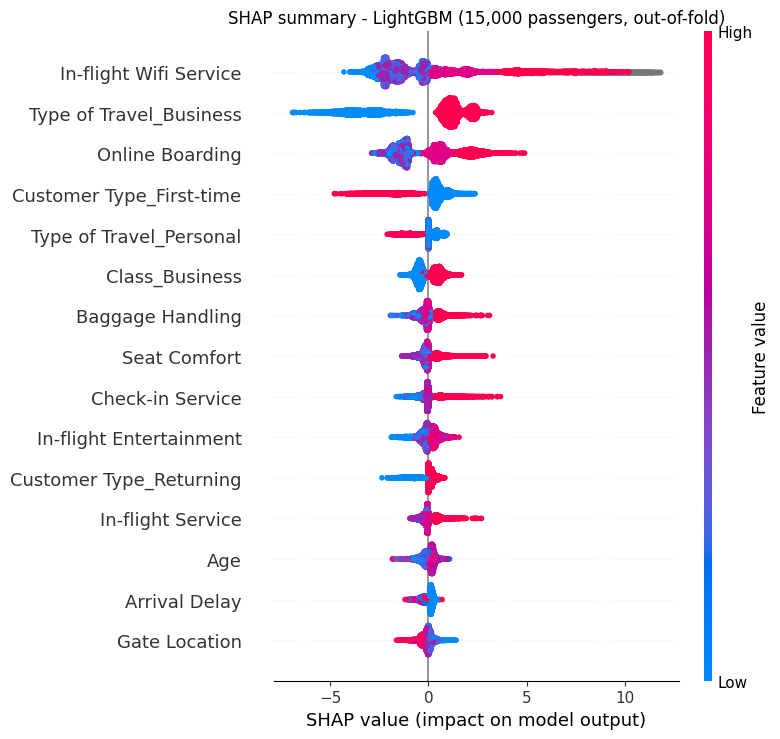

In [18]:
# Cell 18: SHAP values (out-of-fold): 3,000 random test passengers per fold, each explained by the
# fold model that did not train on them (15,000 passengers in total; exact TreeSHAP is slow on all 129,880)
N_SHAP_PER_FOLD = 3000
rs = np.random.RandomState(SEED)
shap_parts, idx_parts = [], []
for s, f in enumerate(folds):
    pick = rs.choice(len(f['te_idx']), N_SHAP_PER_FOLD, replace=False)
    t0 = time.time()
    sv = shap.TreeExplainer(best_models[s]).shap_values(f['raw_te'].iloc[pick])
    sv = np.asarray(sv[1] if isinstance(sv, list) else sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    shap_parts.append(sv.astype('float32'))
    idx_parts.append(f['te_idx'][pick])
    print(f'Fold {s + 1}: SHAP done ({time.time() - t0:.0f}s)')
shap_idx = np.concatenate(idx_parts)
shap_all = np.vstack(shap_parts)
Xs = X.iloc[shap_idx].reset_index(drop=True)
seg_s = segments.iloc[shap_idx].reset_index(drop=True)
mean_abs = pd.Series(np.abs(shap_all).mean(axis=0), index=feature_names).sort_values(ascending=False)
mean_abs.to_csv(f'{OUT_DIR}/shap_mean_abs.csv')
print(mean_abs.head(15).round(4).to_string())
np.save(f'{OUT_DIR}/shap_values_oof.npy', shap_all)
np.save(f'{OUT_DIR}/shap_passenger_index.npy', shap_idx)

plt.figure()
shap.summary_plot(shap_all, features=Xs, feature_names=feature_names, max_display=15, show=False)
plt.title('SHAP summary - LightGBM (15,000 passengers, out-of-fold)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_shap_beeswarm.png', dpi=300, bbox_inches='tight'); plt.show()

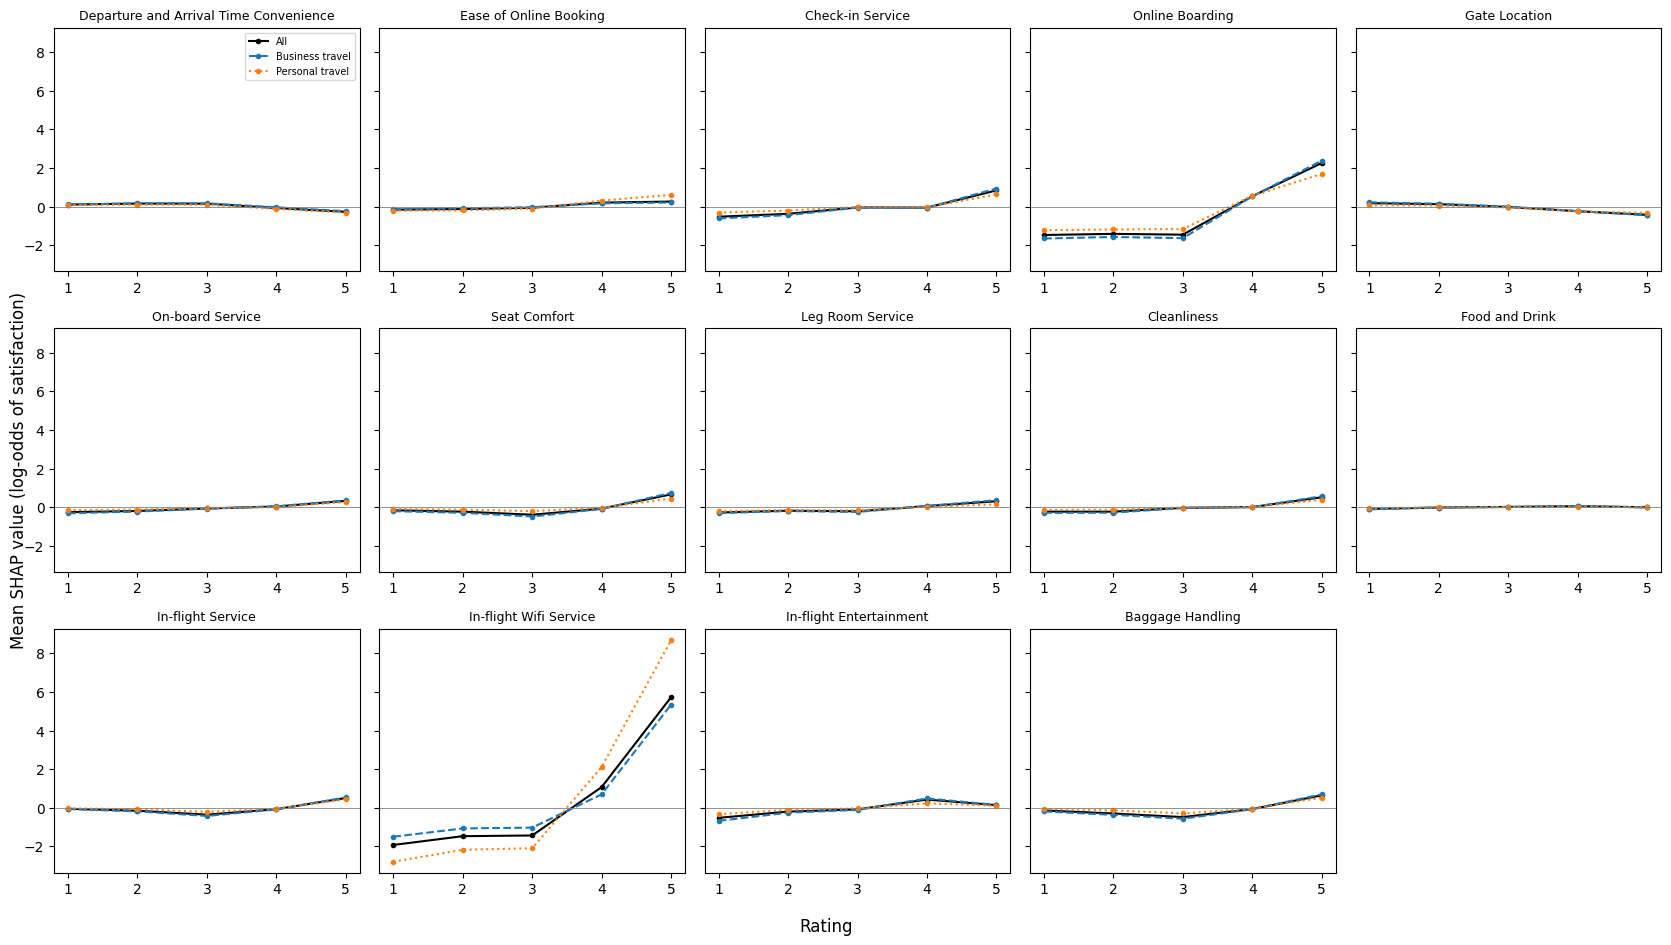

In [19]:
# Cell 19: Mean SHAP value at each rating level, per attribute (all passengers and by type of travel)
level_rows = []
for c in service_cols:
    j = feature_names.index(c)
    for seg_name, mask in [('All', np.ones(len(Xs), bool)),
                           ('Business travel', (seg_s['Type of Travel'] == 'Business').values),
                           ('Personal travel', (seg_s['Type of Travel'] == 'Personal').values)]:
        for r in [1, 2, 3, 4, 5]:
            sel = mask & (Xs[c].values == r)
            level_rows.append({'Attribute': c, 'Segment': seg_name, 'Rating': r, 'Passengers': int(sel.sum()),
                               'Mean SHAP': float(shap_all[sel, j].mean()) if sel.any() else np.nan})
level_df = pd.DataFrame(level_rows)
level_df.to_csv(f'{OUT_DIR}/table_shap_by_rating.csv', index=False)

fig, axes = plt.subplots(3, 5, figsize=(17, 9.5), sharey=True)
for ax, c in zip(axes.ravel(), service_cols):
    for seg_name, st in [('All', 'k-'), ('Business travel', 'C0--'), ('Personal travel', 'C1:')]:
        d = level_df[(level_df['Attribute'] == c) & (level_df['Segment'] == seg_name)]
        ax.plot(d['Rating'], d['Mean SHAP'], st, marker='o', ms=3, label=seg_name)
    ax.axhline(0, color='grey', lw=0.6); ax.set_title(c, fontsize=9); ax.set_xticks([1, 2, 3, 4, 5])
axes.ravel()[-1].axis('off')
axes[0, 0].legend(fontsize=7)
fig.supylabel('Mean SHAP value (log-odds of satisfaction)'); fig.supxlabel('Rating')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_shap_by_rating.png', dpi=300); plt.show()

In [20]:
# Cell 20: Penalty, reward and impact asymmetry with bootstrap intervals, by segment
seg_defs = [('All passengers', np.ones(len(Xs), bool)),
            ('Business travel', (seg_s['Type of Travel'] == 'Business').values),
            ('Personal travel', (seg_s['Type of Travel'] == 'Personal').values),
            ('Returning customers', (seg_s['Customer Type'] == 'Returning').values),
            ('First-time customers', (seg_s['Customer Type'] == 'First-time').values)]
print({k: int(v.sum()) for k, v in seg_defs})
B = 500
rs = np.random.RandomState(SEED)
asym_rows = []
for seg_name, mask in seg_defs:
    idx_seg = np.where(mask)[0]
    for c in service_cols:
        j = feature_names.index(c)
        v = Xs[c].values[idx_seg]; sv = shap_all[idx_seg, j]
        lo, mid, hi = (v <= 2), (v == 3), (v >= 4)
        # penalty = how much ratings 1-2 lower satisfaction compared with rating 3 (0 if they do not)
        # reward  = how much ratings 4-5 raise satisfaction compared with rating 3 (0 if they do not)
        P_raw = sv[lo].mean() - sv[mid].mean()
        R_raw = sv[hi].mean() - sv[mid].mean()
        Pn, Rw = max(0.0, -P_raw), max(0.0, R_raw)
        IA = (Rw - Pn) / (Rw + Pn) if (Rw + Pn) > 0 else np.nan
        boot = []
        for _ in range(B):
            b = rs.randint(0, len(idx_seg), len(idx_seg))
            svb, lob, midb, hib = sv[b], lo[b], mid[b], hi[b]
            Pb = max(0.0, -(svb[lob].mean() - svb[midb].mean()))
            Rb = max(0.0, svb[hib].mean() - svb[midb].mean())
            boot.append((Rb - Pb) / (Rb + Pb) if (Rb + Pb) > 0 else np.nan)
        ci_lo, ci_hi = np.nanpercentile(boot, [2.5, 97.5])
        perf = np.nanmean(v)
        if R_raw < 0 and P_raw > 0:
            kind = 'Reversed (higher rating, lower satisfaction)'
        elif Rw + Pn < 0.1:
            kind = 'Weak effect'
        elif ci_hi < -0.2:
            kind = 'Basic'
        elif ci_lo > 0.2:
            kind = 'Excitement'
        else:
            kind = 'Performance'
        asym_rows.append({'Segment': seg_name, 'Attribute': c, 'Mean rating': round(perf, 2),
                          'Penalty (1-2 vs 3)': round(P_raw, 3), 'Reward (4-5 vs 3)': round(R_raw, 3), 'Range of impact': round(Rw + Pn, 3),
                          'IA': round(IA, 3), 'IA 95% CI low': round(ci_lo, 3), 'IA 95% CI high': round(ci_hi, 3),
                          'Factor type': kind})
asym_df = pd.DataFrame(asym_rows)
asym_df.to_csv(f'{OUT_DIR}/table_asymmetry.csv', index=False)
print(asym_df[asym_df['Segment'] == 'All passengers'].sort_values('Range of impact', ascending=False).to_string(index=False))

{'All passengers': 15000, 'Business travel': 10332, 'Personal travel': 4668, 'Returning customers': 12235, 'First-time customers': 2765}
       Segment                              Attribute  Mean rating  Penalty (1-2 vs 3)  Reward (4-5 vs 3)  Range of impact     IA  IA 95% CI low  IA 95% CI high                                  Factor type
All passengers                 In-flight Wifi Service         2.80              -0.224              4.220            4.445  0.899          0.885           0.913                                   Excitement
All passengers                        Online Boarding         3.30               0.019              2.682            2.682  1.000          1.000           1.000                                   Excitement
All passengers                       Check-in Service         3.31              -0.407              0.367            0.774 -0.052         -0.071          -0.033                                  Performance
All passengers                       Ba

Segment                                                               All passengers                               Business travel                               Personal travel                           Returning customers                          First-time customers
Attribute                                                                                                                                                                                                                                                                   
Baggage Handling                                                          Excitement                                    Excitement                                    Excitement                                    Excitement                                    Excitement
Check-in Service                                                         Performance                                   Performance                                   Performance                 

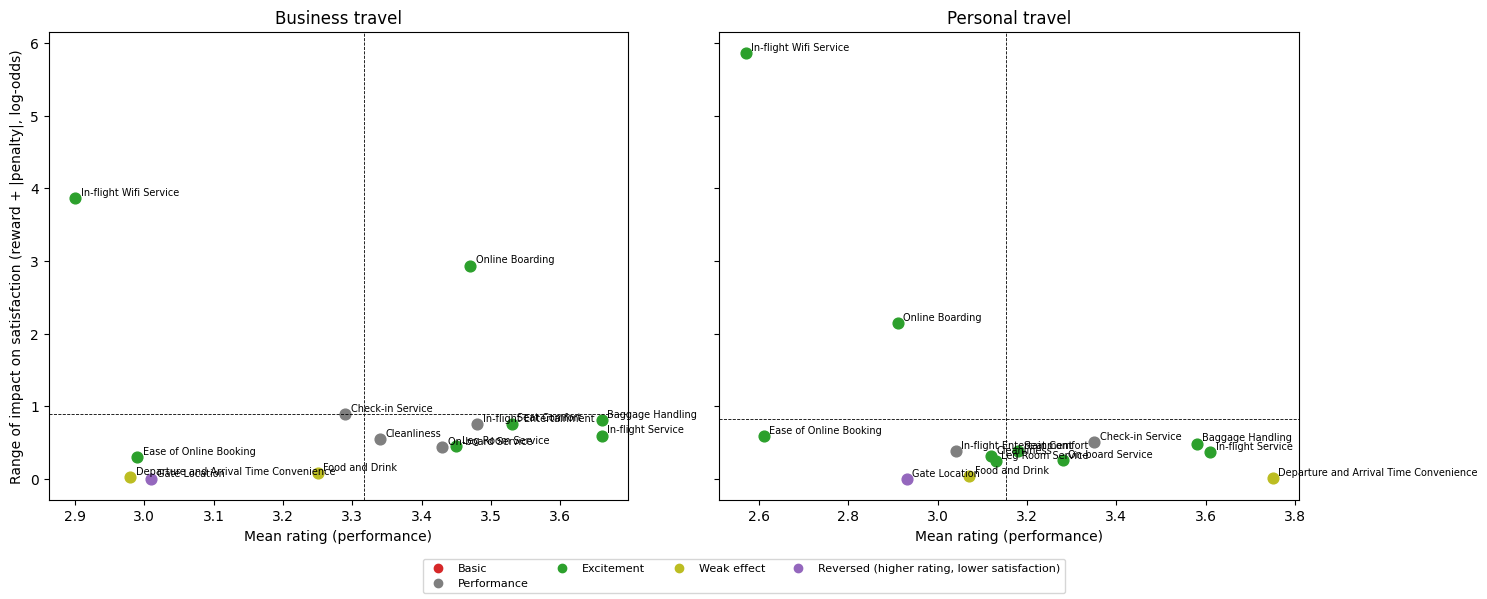

In [21]:
# Cell 21: Factor types side by side for business and personal travellers, and the impact-performance chart
pivot_type = asym_df.pivot(index='Attribute', columns='Segment', values='Factor type')[[s for s, _ in seg_defs]]
pivot_type.to_csv(f'{OUT_DIR}/table_factor_types_by_segment.csv')
print(pivot_type.to_string())

colors = {'Basic': 'tab:red', 'Performance': 'tab:grey', 'Excitement': 'tab:green', 'Weak effect': 'tab:olive',
          'Reversed (higher rating, lower satisfaction)': 'tab:purple'}
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, seg_name in zip(axes, ['Business travel', 'Personal travel']):
    d = asym_df[asym_df['Segment'] == seg_name]
    for _, r in d.iterrows():
        ax.scatter(r['Mean rating'], r['Range of impact'], color=colors[r['Factor type']], s=60)
        ax.annotate(r['Attribute'], (r['Mean rating'], r['Range of impact']), fontsize=7, xytext=(4, 2), textcoords='offset points')
    ax.axvline(d['Mean rating'].mean(), color='k', lw=0.6, ls='--'); ax.axhline(d['Range of impact'].mean(), color='k', lw=0.6, ls='--')
    ax.set_title(seg_name); ax.set_xlabel('Mean rating (performance)')
axes[0].set_ylabel('Range of impact on satisfaction (reward + |penalty|, log-odds)')
handles = [plt.Line2D([], [], marker='o', ls='', color=v, label=k) for k, v in colors.items()]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=8)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.savefig(f'{OUT_DIR}/fig_impact_performance.png', dpi=300); plt.show()

## 9. Top-rating effect by segment

The penalty-reward contrast above cannot identify basic factors here, because the outcome merges neutral and dissatisfied passengers (Section 4.4 of the paper). The paper therefore uses the **top-rating effect**: the difference in mean SHAP value between passengers who rated a service 4–5 and those who rated it 1–3, by segment, with 95% bootstrap intervals, and the difference between segments.

Segment                                 All passengers  Business travel  Personal travel  Returning customers  First-time customers
Attribute                                                                                                                          
In-flight Wifi Service                            4.36             3.78             5.74                 4.21                  5.03
Online Boarding                                   2.67             2.92             2.13                 2.69                  2.47
Baggage Handling                                  0.60             0.69             0.39                 0.62                  0.47
Check-in Service                                  0.56             0.64             0.37                 0.57                  0.50
Seat Comfort                                      0.53             0.64             0.33                 0.58                  0.37
In-flight Entertainment                           0.53             0.63     

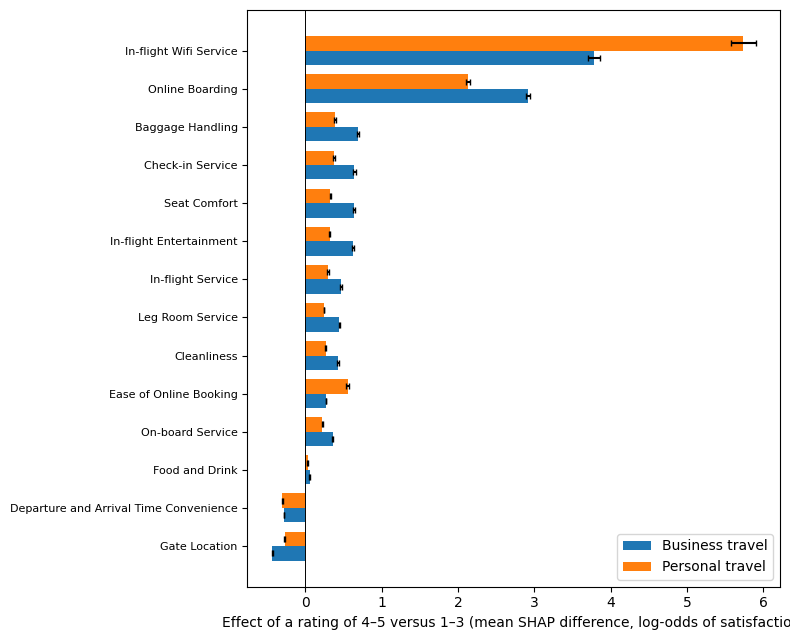

In [22]:
# Cell 22 (revised: no longer overwrites `df` or the label vector `y`; numbers unchanged): Top-rating effects and segment differences (Table 5 and Figure 3 of the paper)
# Effect of a top rating (4-5) versus 1-3 on the log-odds of satisfaction, from out-of-fold SHAP values,
# by travel purpose and customer type, with 95% bootstrap intervals (500 resamples).
df_raw=pd.read_csv(DATA_PATH)
svc=['Departure and Arrival Time Convenience','Ease of Online Booking','Check-in Service','Online Boarding','Gate Location',
     'On-board Service','Seat Comfort','Leg Room Service','Cleanliness','Food and Drink','In-flight Service',
     'In-flight Wifi Service','In-flight Entertainment','Baggage Handling']
cols=list(pd.get_dummies(df_raw.drop(columns=['ID','Satisfaction']),columns=['Gender','Customer Type','Type of Travel','Class']).columns)
sv=np.load(f'{OUT_DIR}/shap_values_oof.npy'); idx=np.load(f'{OUT_DIR}/shap_passenger_index.npy')
R=df_raw[svc].replace(0,np.nan).iloc[idx].reset_index(drop=True); seg=df_raw[['Type of Travel','Customer Type']].iloc[idx].reset_index(drop=True)
segs=[('All passengers',np.ones(len(R),bool)),('Business travel',(seg['Type of Travel']=='Business').values),
      ('Personal travel',(seg['Type of Travel']=='Personal').values),('Returning customers',(seg['Customer Type']=='Returning').values),
      ('First-time customers',(seg['Customer Type']=='First-time').values)]
rs=np.random.RandomState(42); rows=[]
for c in svc:
    j=cols.index(c); v=R[c].values; s=sv[:,j]
    for name,m in segs:
        ii=np.where(m&~np.isnan(v))[0]; vv,ss=v[ii],s[ii]
        top=vv>=4; d=ss[top].mean()-ss[~top].mean()
        bs=[]
        for _ in range(500):
            b=rs.randint(0,len(ii),len(ii)); t=vv[b]>=4; bs.append(ss[b][t].mean()-ss[b][~t].mean())
        lo,hi=np.percentile(bs,[2.5,97.5])
        # share of the 1->5 rise that happens between 3 and 4
        lev={r:ss[vv==r].mean() for r in [1,2,3,4,5]}
        rows.append({'Attribute':c,'Segment':name,'Passengers':len(ii),'Top-rating effect':round(d,3),'CI low':round(lo,3),'CI high':round(hi,3),
                     **{f'Mean SHAP {r}':round(lev[r],3) for r in lev}})
t=pd.DataFrame(rows); t.to_csv(f'{OUT_DIR}/table_top_rating_effects.csv',index=False)
p=t.pivot(index='Attribute',columns='Segment',values='Top-rating effect')[[s for s,_ in segs]].sort_values('All passengers',ascending=False)
print(p.round(2).to_string())
# segment differences with CI (personal - business; first-time - returning)
diff=[]
for c in svc:
    j=cols.index(c); v=R[c].values; s=sv[:,j]; ok=~np.isnan(v)
    for a,bn,col,va,vb in [('Personal','Business','Type of Travel','Personal','Business'),('First-time','Returning','Customer Type','First-time','Returning')]:
        g=seg[col].values
        def eff(vv,ss,gg,val):
            m=(gg==val); t=vv[m]>=4; return ss[m][t].mean()-ss[m][~t].mean()
        ii=np.where(ok)[0]; est=eff(v[ii],s[ii],g[ii],va)-eff(v[ii],s[ii],g[ii],vb); bs=[]
        for _ in range(500):
            b=ii[rs.randint(0,len(ii),len(ii))]; bs.append(eff(v[b],s[b],g[b],va)-eff(v[b],s[b],g[b],vb))
        lo,hi=np.percentile(bs,[2.5,97.5]); diff.append({'Attribute':c,'Contrast':f'{a} minus {bn}','Difference':round(est,3),'CI low':round(lo,3),'CI high':round(hi,3)})
dd=pd.DataFrame(diff); dd.to_csv(f'{OUT_DIR}/table_segment_differences.csv',index=False); print(dd.to_string(index=False))
# figure: top-rating effect by travel purpose
order=p.index[::-1]
fig,ax=plt.subplots(figsize=(8,6.5)); ypos=np.arange(len(order)); h=0.38
for k,(name,col) in enumerate([('Business travel','tab:blue'),('Personal travel','tab:orange')]):
    d=t[t.Segment==name].set_index('Attribute').loc[order]
    ax.barh(ypos+(k-0.5)*h,d['Top-rating effect'],h,xerr=[d['Top-rating effect']-d['CI low'],d['CI high']-d['Top-rating effect']],color=col,label=name,capsize=2)
ax.set_yticks(ypos); ax.set_yticklabels(order,fontsize=8); ax.axvline(0,color='k',lw=0.7)
ax.set_xlabel('Effect of a rating of 4–5 versus 1–3 (mean SHAP difference, log-odds of satisfaction)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_top_rating_effects.png',dpi=300); plt.show()


## 10. Additional analyses for the journal revision

Cells 24–31 are required; Cell 32 and Cell 33 are optional. They do not change any earlier result.
Each cell prints what the manuscript needs and saves a CSV to `results_air/`.

In [23]:
# Cell 24: Reproducibility record - versions, candidate lists, chosen configurations, stopping iterations
import sys, sklearn, scipy, statsmodels
raw = pd.read_csv(DATA_PATH)                                   # untouched copy of the data (0 = not applicable)
y_lab = (raw['Satisfaction'] == 'Satisfied').astype(int).values  # label vector used by Cells 24-33
assert (y_lab == (df['Satisfaction'] == 'Satisfied').astype(int).values).all()
print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| scipy', scipy.__version__, '| statsmodels', statsmodels.__version__, '| XGBoost', xgb.__version__,
      '| LightGBM', lgb.__version__, '| SHAP', shap.__version__)
rf_list = pd.DataFrame(rf_configs).astype(str)
print('\nRandom forest candidate list:'); print(rf_list.to_string())
print('Distinct random forest configurations:', rf_list.drop_duplicates().shape[0])
print('\nChosen configuration per fold:'); print(chosen_df.to_string(index=False))
print('\nLightGBM configurations chosen:')
for k in sorted(set(results_df[results_df['Model'] == 'LightGBM']['Chosen config'])):
    print(k, lgb_configs[int(k)])
print('LightGBM stopping iterations per fold:', [int(best_models[s].best_iteration_) for s in range(N_FOLDS)])

Python 3.13.15 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | scipy 1.16.3 | statsmodels 0.15.0 | XGBoost 3.4.1 | LightGBM 4.6.0 | SHAP 0.52.0

Random forest candidate list:
  max_depth min_samples_leaf max_features
0        30                1         sqrt
1        30                1         sqrt
2        30                2         sqrt
3        30                5         sqrt
Distinct random forest configurations: 3

Chosen configuration per fold:
              Model  Fold  Validation ROC-AUC    C  max_depth  min_samples_leaf max_features  learning_rate  subsample  colsample_bytree  min_child_weight  reg_lambda  num_leaves  min_child_samples
Logistic Regression     1              0.9657  1.0        NaN               NaN          NaN            NaN        NaN               NaN               NaN         NaN         NaN                NaN
Logistic Regression     2              0.9641 10.0        NaN               NaN          NaN            NaN        NaN               NaN      

In [24]:
# Cell 25: Table IV source - share satisfied at each rating (0 shown separately), with counts;
# zero-rating outcome check; in-flight Wi-Fi by travel purpose; customer-type share
rows = []
for c in service_cols:
    row = {'Service': c}
    for r in [0, 1, 2, 3, 4, 5]:
        m = (raw[c] == r).values
        row[f'n {r}'] = int(m.sum())
        row[f'% sat {r}'] = round(100 * y_lab[m].mean(), 1) if m.any() else np.nan
    rows.append(row)
table4 = pd.DataFrame(rows)
table4.to_csv(f'{OUT_DIR}/table_satisfaction_by_rating.csv', index=False)
print(table4.to_string(index=False))
any_zero = (raw[service_cols] == 0).any(axis=1).values
print(f'\nSatisfied: passengers with any 0 rating {100 * y_lab[any_zero].mean():.1f}% | no 0 rating {100 * y_lab[~any_zero].mean():.1f}%')
wifi_tab = pd.crosstab(raw['Type of Travel'], raw['In-flight Wifi Service'], values=y_lab, aggfunc='mean').mul(100).round(1)
wifi_n = pd.crosstab(raw['Type of Travel'], raw['In-flight Wifi Service'])
print('\n% satisfied by Wi-Fi rating and travel purpose:'); print(wifi_tab.to_string())
print('Counts:'); print(wifi_n.to_string())
wifi_tab.to_csv(f'{OUT_DIR}/table_wifi_by_travel.csv')
print('\nCustomer type share:', raw['Customer Type'].value_counts(normalize=True).round(4).to_dict())

                               Service  n 0  % sat 0   n 1  % sat 1   n 2  % sat 2   n 3  % sat 3   n 4  % sat 4   n 5  % sat 5
Departure and Arrival Time Convenience 6681     48.1 19409     49.0 21534     44.5 22378     44.0 31880     38.9 27998     42.5
                Ease of Online Booking 5682     66.6 21886     37.9 30051     30.3 30393     31.0 24444     53.2 17424     73.5
                      Check-in Service    1      0.0 16108     24.0 16102     25.1 35453     45.1 36333     46.0 25883     61.2
                       Online Boarding 3080     56.5 13261     13.8 21934     11.5 27117     13.8 38468     62.3 26020     87.1
                         Gate Location    1    100.0 21991     49.9 24296     46.4 35717     34.7 30466     39.1 17409     56.8
                      On-board Service    5      0.0 14787     19.7 18351     25.5 28542     31.8 38703     53.5 29492     64.6
                          Seat Comfort    1      0.0 15108     22.3 18529     22.6 23328     21.4 39756 

In [25]:
# Cell 26: Values quoted in Section IV that were saved but never printed
# (a) mean SHAP and passenger count at each rating; (b) importance with the two dummies of each
# categorical variable summed per passenger (valid because SHAP values are additive); (c) Spearman correlations
lv = pd.read_csv(f'{OUT_DIR}/table_shap_by_rating.csv')
print(lv[lv['Segment'] == 'All'].pivot(index='Attribute', columns='Rating', values='Mean SHAP').round(3).to_string())
print(lv[lv['Segment'] == 'All'].pivot(index='Attribute', columns='Rating', values='Passengers').to_string())
grp = {'Type of Travel': [f for f in feature_names if f.startswith('Type of Travel_')],
       'Customer Type': [f for f in feature_names if f.startswith('Customer Type_')],
       'Class': [f for f in feature_names if f.startswith('Class_')],
       'Gender': [f for f in feature_names if f.startswith('Gender_')]}
in_grp = sum(grp.values(), [])
g_imp = {g: float(np.abs(shap_all[:, [feature_names.index(f) for f in fs]].sum(axis=1)).mean()) for g, fs in grp.items()}
for f in feature_names:
    if f not in in_grp:
        g_imp[f] = float(np.abs(shap_all[:, feature_names.index(f)]).mean())
g_imp = pd.Series(g_imp).sort_values(ascending=False)
g_imp.to_csv(f'{OUT_DIR}/shap_mean_abs_grouped.csv')
print('\nMean |SHAP| with dummies grouped:'); print(g_imp.round(4).to_string())
rho = raw[service_cols].replace(0, np.nan).corr(method='spearman')
rho.round(2).to_csv(f'{OUT_DIR}/table_spearman_ratings.csv')
print('\nSpearman correlations (zeros excluded):'); print(rho.round(2).to_string())

Rating                                      1      2      3      4      5
Attribute                                                                
Baggage Handling                       -0.136 -0.293 -0.479 -0.062  0.648
Check-in Service                       -0.528 -0.378 -0.047 -0.058  0.834
Cleanliness                            -0.233 -0.231 -0.035  0.005  0.514
Departure and Arrival Time Convenience  0.100  0.153  0.149 -0.078 -0.275
Ease of Online Booking                 -0.163 -0.132 -0.062  0.202  0.257
Food and Drink                         -0.090 -0.018  0.012  0.051 -0.008
Gate Location                           0.174  0.119 -0.024 -0.243 -0.431
In-flight Entertainment                -0.517 -0.195 -0.079  0.429  0.140
In-flight Service                      -0.047 -0.150 -0.354 -0.071  0.509
In-flight Wifi Service                 -1.923 -1.468 -1.432  1.075  5.730
Leg Room Service                       -0.275 -0.182 -0.214  0.055  0.309
On-board Service                      

In [26]:
# Cell 27: Adjacent-rating contrasts mu(r+1) - mu(r) of mean SHAP, with 95% intervals from 2,000 passenger
# bootstrap resamples (conditional on the fitted fold models). Tests whether the change is concentrated at 3->4.
B_ADJ = 2000
rs_adj = np.random.RandomState(SEED)
R_s = raw[service_cols].replace(0, np.nan).iloc[shap_idx].reset_index(drop=True)
seg_x = raw[['Type of Travel', 'Customer Type', 'Class']].iloc[shap_idx].reset_index(drop=True)
adj_rows = []
for seg_name, mask in [('All passengers', np.ones(len(R_s), bool)),
                       ('Business travel', (seg_x['Type of Travel'] == 'Business').values),
                       ('Personal travel', (seg_x['Type of Travel'] == 'Personal').values)]:
    for c in service_cols:
        j = feature_names.index(c)
        ii = np.where(mask & R_s[c].notna().values)[0]
        vv, ss = R_s[c].values[ii], shap_all[ii, j]
        est = np.diff([ss[vv == r].mean() for r in [1, 2, 3, 4, 5]])
        boots = np.empty((B_ADJ, 4))
        for b in range(B_ADJ):
            bi = rs_adj.randint(0, len(ii), len(ii))
            vb, sb = vv[bi], ss[bi]
            boots[b] = np.diff([sb[vb == r].mean() for r in [1, 2, 3, 4, 5]])
        lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
        for k, step in enumerate(['1->2', '2->3', '3->4', '4->5']):
            adj_rows.append({'Segment': seg_name, 'Attribute': c, 'Step': step, 'Contrast': round(est[k], 3),
                             'CI low': round(lo[k], 3), 'CI high': round(hi[k], 3)})
adj_df = pd.DataFrame(adj_rows)
adj_df.to_csv(f'{OUT_DIR}/table_adjacent_contrasts.csv', index=False)
print(adj_df[adj_df['Segment'] == 'All passengers'].to_string(index=False))
print(adj_df[adj_df['Attribute'].isin(['In-flight Wifi Service', 'Online Boarding']) & (adj_df['Segment'] != 'All passengers')].to_string(index=False))

       Segment                              Attribute Step  Contrast  CI low  CI high
All passengers Departure and Arrival Time Convenience 1->2     0.053   0.045    0.061
All passengers Departure and Arrival Time Convenience 2->3    -0.004  -0.010    0.002
All passengers Departure and Arrival Time Convenience 3->4    -0.227  -0.231   -0.222
All passengers Departure and Arrival Time Convenience 4->5    -0.198  -0.203   -0.192
All passengers                 Ease of Online Booking 1->2     0.031   0.025    0.036
All passengers                 Ease of Online Booking 2->3     0.070   0.065    0.074
All passengers                 Ease of Online Booking 3->4     0.264   0.259    0.270
All passengers                 Ease of Online Booking 4->5     0.055   0.043    0.066
All passengers                       Check-in Service 1->2     0.150   0.136    0.163
All passengers                       Check-in Service 2->3     0.331   0.322    0.340
All passengers                       Check-in Service 

In [27]:
# Cell 28: Corrected factor labels for the penalty-reward check (Cell 20)
# Cell 20 clips a NEGATIVE reward to 0 and then labels the attribute 'Weak effect', so an attribute whose
# ratings of 4-5 have LOWER attributions than rating 3 can be labelled weak instead of reversed.
fixed = asym_df.copy()
fixed['Factor type (corrected)'] = np.where(fixed['Reward (4-5 vs 3)'] < -0.1, 'Reversed (top ratings below rating 3)', fixed['Factor type'])
changed = fixed[fixed['Factor type'] != fixed['Factor type (corrected)']]
print('Labels changed by the correction:'); print(changed[['Segment', 'Attribute', 'Penalty (1-2 vs 3)', 'Reward (4-5 vs 3)', 'Factor type', 'Factor type (corrected)']].to_string(index=False))
print('\nBasic factors in any segment after correction:', int((fixed['Factor type (corrected)'] == 'Basic').sum()))
fixed.to_csv(f'{OUT_DIR}/table_asymmetry_corrected.csv', index=False)

Labels changed by the correction:
             Segment                              Attribute  Penalty (1-2 vs 3)  Reward (4-5 vs 3)                                  Factor type               Factor type (corrected)
      All passengers Departure and Arrival Time Convenience              -0.021             -0.320                                  Weak effect Reversed (top ratings below rating 3)
      All passengers                          Gate Location               0.169             -0.288 Reversed (higher rating, lower satisfaction) Reversed (top ratings below rating 3)
     Business travel Departure and Arrival Time Convenience              -0.027             -0.298                                  Weak effect Reversed (top ratings below rating 3)
     Business travel                          Gate Location               0.187             -0.321 Reversed (higher rating, lower satisfaction) Reversed (top ratings below rating 3)
     Personal travel Departure and Arrival Time Convenie

In [28]:
# Cell 29: Adjusted subgroup check - top-rating contrast (4-5 vs 1-3) by travel purpose WITHIN each cabin class,
# and a class-standardised personal-minus-business difference with a 500-resample passenger bootstrap
classes = ['Business', 'Economy', 'Economy Plus']
w_cls = seg_x['Class'].value_counts(normalize=True).reindex(classes).values
rs_cls = np.random.RandomState(SEED)
strat_rows, std_rows = [], []
for c in service_cols:
    j = feature_names.index(c)
    ok = R_s[c].notna().values
    v_all, s_all, cl_all, tt_all = R_s[c].values[ok], shap_all[ok, j], seg_x['Class'].values[ok], seg_x['Type of Travel'].values[ok]
    within = {}
    for cl in classes:
        for tt in ['Business', 'Personal']:
            m = (cl_all == cl) & (tt_all == tt)
            top, low = m & (v_all >= 4), m & (v_all <= 3)
            within[(cl, tt)] = s_all[top].mean() - s_all[low].mean() if top.any() and low.any() else np.nan
            strat_rows.append({'Attribute': c, 'Class': cl, 'Travel': tt, 'n': int(m.sum()), 'n rated 4-5': int(top.sum()),
                               'Top-rating contrast': round(within[(cl, tt)], 3)})
    est = float(np.sum(w_cls * np.array([within[(cl, 'Personal')] - within[(cl, 'Business')] for cl in classes])))
    boots = []
    for b in range(500):
        bi = rs_cls.randint(0, len(v_all), len(v_all))
        vb, sb, clb, ttb = v_all[bi], s_all[bi], cl_all[bi], tt_all[bi]
        d = []
        for cl in classes:
            e = {}
            for tt in ['Business', 'Personal']:
                m = (clb == cl) & (ttb == tt)
                e[tt] = sb[m & (vb >= 4)].mean() - sb[m & (vb <= 3)].mean()
            d.append(e['Personal'] - e['Business'])
        boots.append(np.sum(w_cls * np.array(d)))
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    std_rows.append({'Attribute': c, 'Class-standardised personal minus business': round(est, 3), 'CI low': round(lo, 3), 'CI high': round(hi, 3)})
strat_df = pd.DataFrame(strat_rows); std_df_cls = pd.DataFrame(std_rows)
strat_df.to_csv(f'{OUT_DIR}/table_class_stratified_contrasts.csv', index=False)
std_df_cls.to_csv(f'{OUT_DIR}/table_class_standardised_differences.csv', index=False)
print(strat_df.pivot_table(index=['Attribute', 'Class'], columns='Travel', values='Top-rating contrast').round(2).to_string())
print(); print(strat_df.pivot_table(index=['Attribute', 'Class'], columns='Travel', values='n rated 4-5').to_string())
print(); print(std_df_cls.to_string(index=False))

Travel                                               Business  Personal
Attribute                              Class                           
Baggage Handling                       Business          0.84      0.47
                                       Economy           0.44      0.39
                                       Economy Plus      0.35      0.35
Check-in Service                       Business          0.63      0.40
                                       Economy           0.59      0.37
                                       Economy Plus      0.67      0.37
Cleanliness                            Business          0.46      0.31
                                       Economy           0.33      0.26
                                       Economy Plus      0.39      0.27
Departure and Arrival Time Convenience Business         -0.32     -0.38
                                       Economy          -0.19     -0.30
                                       Economy Plus     -0.20   

In [29]:
# Cell 30: Sensitivity to zero ratings - refit LightGBM (fold configuration reused) on passengers with NO zero rating,
# recompute out-of-fold SHAP (3,000 test passengers per fold) and the main contrasts
nz = ~(df_raw_ratings == 0).any(axis=1).values
X_nz, y_nz = X[nz].reset_index(drop=True), y_lab[nz]
R_nz = raw.loc[nz, service_cols].reset_index(drop=True)
tt_nz = raw.loc[nz, 'Type of Travel'].reset_index(drop=True).values
print('Passengers without any zero rating:', int(nz.sum()))
rs_nz = np.random.RandomState(SEED)
sv_nz, id_nz, perf_nz = [], [], []
for s, (tr, te) in enumerate(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_nz, y_nz)):
    cfg = lgb_configs[int(results_df[(results_df['Model'] == 'LightGBM') & (results_df['Fold'] == s + 1)]['Chosen config'].iloc[0])]
    Xa, Xv, ya, yv = train_test_split(X_nz.iloc[tr], y_nz[tr], test_size=0.1, stratify=y_nz[tr], random_state=SEED)
    m_nz = lgb.LGBMClassifier(n_estimators=2000, subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1, **cfg)
    m_nz.fit(Xa, ya, eval_set=[(Xv, yv)], eval_metric='binary_logloss', callbacks=[lgb.early_stopping(50, verbose=False)])
    p_nz = m_nz.predict_proba(X_nz.iloc[te])[:, 1]
    perf_nz.append({'Fold': s + 1, 'Accuracy': accuracy_score(y_nz[te], p_nz >= 0.5), 'F1': f1_score(y_nz[te], p_nz >= 0.5),
                    'ROC-AUC': roc_auc_score(y_nz[te], p_nz)})
    pick = rs_nz.choice(len(te), N_SHAP_PER_FOLD, replace=False)
    sv = shap.TreeExplainer(m_nz).shap_values(X_nz.iloc[te[pick]])
    sv = np.asarray(sv[1] if isinstance(sv, list) else sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    sv_nz.append(sv); id_nz.append(te[pick])
    print(f'Fold {s + 1} done')
perf_nz = pd.DataFrame(perf_nz)
print(perf_nz.round(4).to_string(index=False)); print('Mean:', perf_nz.drop(columns='Fold').mean().round(4).to_dict())
S_nz = np.vstack(sv_nz); I_nz = np.concatenate(id_nz)
rows = []
rs_b = np.random.RandomState(SEED)
for c in service_cols:
    j = feature_names.index(c); v = R_nz[c].values[I_nz]; sj = S_nz[:, j]; tt = tt_nz[I_nz]
    lev = {f'Mean SHAP {r}': round(sj[v == r].mean(), 3) for r in [1, 2, 3, 4, 5]}
    eff = {}
    for name, m in [('All', np.ones(len(v), bool)), ('Business', tt == 'Business'), ('Personal', tt == 'Personal')]:
        eff[name] = sj[m & (v >= 4)].mean() - sj[m & (v <= 3)].mean()
    diff_b = []
    for b in range(500):
        bi = rs_b.randint(0, len(v), len(v)); vb, sb, tb = v[bi], sj[bi], tt[bi]
        e = [sb[(tb == g) & (vb >= 4)].mean() - sb[(tb == g) & (vb <= 3)].mean() for g in ['Personal', 'Business']]
        diff_b.append(e[0] - e[1])
    lo, hi = np.percentile(diff_b, [2.5, 97.5])
    rows.append({'Attribute': c, **lev, 'Top-rating contrast (all)': round(eff['All'], 3), 'Business': round(eff['Business'], 3),
                 'Personal': round(eff['Personal'], 3), 'Personal minus business': round(eff['Personal'] - eff['Business'], 3),
                 'CI low': round(lo, 3), 'CI high': round(hi, 3)})
nz_df = pd.DataFrame(rows)
nz_df.to_csv(f'{OUT_DIR}/table_sensitivity_no_zero_ratings.csv', index=False)
print(nz_df.to_string(index=False))

Passengers without any zero rating: 119567
Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done
Fold 5 done
 Fold  Accuracy     F1  ROC-AUC
    1    0.9665 0.9600   0.9954
    2    0.9660 0.9595   0.9955
    3    0.9652 0.9585   0.9957
    4    0.9641 0.9571   0.9954
    5    0.9658 0.9591   0.9956
Mean: {'Accuracy': 0.9655, 'F1': 0.9589, 'ROC-AUC': 0.9955}
                             Attribute  Mean SHAP 1  Mean SHAP 2  Mean SHAP 3  Mean SHAP 4  Mean SHAP 5  Top-rating contrast (all)  Business  Personal  Personal minus business  CI low  CI high
Departure and Arrival Time Convenience        0.075        0.095        0.096       -0.063       -0.297                     -0.262    -0.236    -0.275                   -0.040  -0.049   -0.031
                Ease of Online Booking       -0.157       -0.132       -0.054        0.204        0.294                      0.351     0.277     0.585                    0.308   0.288    0.325
                      Check-in Service       -0.505       -0.356  

In [30]:
# Cell 31: LightGBM vs XGBoost - corrected resampled t-test (Nadeau and Bengio, 2003) on the five fold scores.
# The correction (1/k + n_test/n_train) accounts for overlapping training sets.
from scipy import stats
n_te = len(folds[0]['y_te']); n_tr = len(folds[0]['y_in']) + len(folds[0]['y_val'])
cmp_rows = []
for met in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    a = results_df[results_df['Model'] == 'LightGBM'].sort_values('Fold')[met].values
    b = results_df[results_df['Model'] == 'XGBoost'].sort_values('Fold')[met].values
    d = a - b; k = len(d)
    t_c = d.mean() / np.sqrt((1 / k + n_te / n_tr) * d.var(ddof=1))
    cmp_rows.append({'Metric': met, 'Mean difference': round(d.mean(), 4), 'Folds LightGBM higher': int((d > 0).sum()),
                     'Corrected t': round(t_c, 2), 'p (two-sided)': round(2 * stats.t.sf(abs(t_c), k - 1), 3)})
cmp_df = pd.DataFrame(cmp_rows); cmp_df.to_csv(f'{OUT_DIR}/table_corrected_ttest.csv', index=False)
print(cmp_df.to_string(index=False))

   Metric  Mean difference  Folds LightGBM higher  Corrected t  p (two-sided)
 Accuracy           0.0008                      4         1.96          0.121
Precision           0.0019                      4         1.69          0.167
   Recall           0.0001                      3         0.17          0.871
       F1           0.0009                      4         1.96          0.121
  ROC-AUC           0.0002                      5         2.71          0.053
   PR-AUC           0.0002                      5         2.69          0.054


In [ ]:
# Cell 35: Publication versions of Figs. 1-3 (IEEE double-column width, readable labels, log-odds axes).
# Uses only files saved in results_air/ and the data file, so it can be run on its own after Cell 22.
plt.rcParams.update({'font.family': 'serif', 'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8,
                     'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7})
sv_f = np.load(f'{OUT_DIR}/shap_values_oof.npy')
id_f = np.load(f'{OUT_DIR}/shap_passenger_index.npy')
raw_f = pd.read_csv(DATA_PATH)
X_f = pd.get_dummies(raw_f.drop(columns=['ID', 'Satisfaction']), columns=['Gender', 'Customer Type', 'Type of Travel', 'Class'], dtype=float)
X_f[service_cols] = X_f[service_cols].replace(0, np.nan)
cols_f = X_f.columns.tolist()
X_f = X_f.iloc[id_f].reset_index(drop=True)
nice = {'In-flight Wifi Service': 'In-flight Wi-Fi', 'Departure and Arrival Time Convenience': 'Dep./arr. time convenience',
        'Ease of Online Booking': 'Ease of online booking', 'Check-in Service': 'Check-in service', 'Online Boarding': 'Online boarding',
        'Gate Location': 'Gate location', 'On-board Service': 'On-board service', 'Seat Comfort': 'Seat comfort',
        'Leg Room Service': 'Leg room', 'Cleanliness': 'Cleanliness', 'Food and Drink': 'Food and drink',
        'In-flight Service': 'In-flight service', 'In-flight Entertainment': 'In-flight entertainment', 'Baggage Handling': 'Baggage handling',
        'Age': 'Age', 'Flight Distance': 'Flight distance', 'Departure Delay': 'Departure delay', 'Arrival Delay': 'Arrival delay',
        'Class_Business': 'Class: business', 'Class_Economy': 'Class: economy', 'Class_Economy Plus': 'Class: economy plus'}
# Fig. 1 - each binary variable shown once: SHAP values of its two dummy columns are summed (SHAP is additive)
pairs = [('Personal travel', 'Type of Travel_Personal', 'Type of Travel_Business'),
         ('First-time customer', 'Customer Type_First-time', 'Customer Type_Returning'),
         ('Female', 'Gender_Female', 'Gender_Male')]
S1, V1, N1 = [], [], []
for lab, a, b in pairs:
    S1.append(sv_f[:, cols_f.index(a)] + sv_f[:, cols_f.index(b)]); V1.append(X_f[a].values); N1.append(lab)
for c in cols_f:
    if c in sum([[a, b] for _, a, b in pairs], []):
        continue
    S1.append(sv_f[:, cols_f.index(c)]); V1.append(X_f[c].values); N1.append(nice.get(c, c))
S1, V1 = np.column_stack(S1), np.column_stack(V1).astype(float)
shap.summary_plot(S1, features=V1, feature_names=N1, max_display=15, show=False)
fig1 = plt.gcf(); fig1.set_size_inches(3.5, 3.9)
for ax in fig1.axes:
    ax.tick_params(labelsize=7)
    ax.set_ylabel(ax.get_ylabel(), fontsize=7)
fig1.axes[0].set_xlabel('SHAP value (log-odds of satisfaction)', fontsize=8)
for coll in fig1.axes[0].collections:
    coll.set_sizes([4])
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig1_shap_summary_ieee.png', dpi=600, bbox_inches='tight'); plt.show()
# Fig. 2 - rating profiles with free y-axes (same means as Cell 19; no new computation)
tt_f = raw_f['Type of Travel'].values[id_f]
fig, axes = plt.subplots(3, 5, figsize=(7.16, 4.6))
for ax, c in zip(axes.ravel(), service_cols):
    j = cols_f.index(c); v = X_f[c].values
    for seg_name, mask, col, ls in [('Business travel', tt_f == 'Business', 'tab:blue', '--'),
                                    ('Personal travel', tt_f == 'Personal', 'tab:orange', ':'),
                                    ('All', np.ones(len(v), bool), 'k', '-')]:
        ii = np.where(mask & ~np.isnan(v))[0]; vv = v[ii]; ss = sv_f[ii, j]
        mu = [ss[vv == r].mean() for r in range(1, 6)]
        ax.plot(range(1, 6), mu, ls, color=col, marker='o', ms=2, lw=0.9, label=seg_name)
    ax.axhline(0, color='grey', lw=0.4); ax.set_title(nice[c], fontsize=7); ax.set_xticks(range(1, 6))
axes.ravel()[-1].axis('off')
h_, l_ = axes[0, 0].get_legend_handles_labels()
axes.ravel()[-1].legend(h_, l_, loc='center', frameon=False)
fig.supylabel('Mean SHAP value (log-odds of satisfaction)', fontsize=8); fig.supxlabel('Rating', fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig2_rating_profiles_ieee.png', dpi=600); plt.show()
# Fig. 3 - top-rating contrast by travel purpose and by customer type, with the 95% intervals from Cell 22
tr_f = pd.read_csv(f'{OUT_DIR}/table_top_rating_effects.csv')
order_f = (tr_f[tr_f['Segment'] == 'All passengers'].set_index('Attribute')['Top-rating effect'].sort_values().index.tolist())
fig, axes = plt.subplots(1, 2, figsize=(7.16, 3.6), sharey=True)
for ax, groups in zip(axes, [[('Business travel', 'tab:blue'), ('Personal travel', 'tab:orange')],
                             [('Returning customers', 'tab:green'), ('First-time customers', 'tab:purple')]]):
    ypos_f = np.arange(len(order_f)); hh = 0.38
    for k, (g, col) in enumerate(groups):
        d = tr_f[tr_f['Segment'] == g].set_index('Attribute').loc[order_f]
        ax.barh(ypos_f + (0.5 - k) * hh, d['Top-rating effect'], hh, color=col, label=g,
                xerr=[d['Top-rating effect'] - d['CI low'], d['CI high'] - d['Top-rating effect']], capsize=1.5, error_kw={'lw': 0.6})
    ax.axvline(0, color='k', lw=0.6); ax.set_yticks(ypos_f); ax.set_yticklabels([nice[c] for c in order_f])
    ax.set_xlabel('Top-rating contrast (log-odds)'); ax.legend(loc='lower right', frameon=False)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig3_top_rating_contrast_ieee.png', dpi=600); plt.show()
print('Saved fig1_shap_summary_ieee.png, fig2_rating_profiles_ieee.png, fig3_top_rating_contrast_ieee.png')


In [4]:
# Cell 34 (Colab only): zip and download all results
!zip -r -q results_air.zip results_air
from google.colab import files
files.download('results_air.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>